# Lab 05 · Simple Linear Regression
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 7** (C-3 Apply, PLO 4 Investigation): *Apply machine learning algorithms and assess their performance using appropriate evaluation metrics.*

**Goal:** build a complete price predictor for one car on real data: prepare the data, split it, train a simple linear regression with the least squares method, test it on unseen ads, and use it.

**Data:** `pakistan_used_cars_clean.csv`, the cleaned OLX Pakistan used-car ads from Lab 03 (Open Data Pakistan, 2021). Use the copy given with this lab so everyone has the same file.

**Rules:** label every output, e.g. `print("T5a:", ...)` · use `random_state=42` for the split · written answers go in Markdown cells · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab05/Lab05.ipynb` by the deadline announced in class (11:59 PM PKT).

Name: Kamal Ali Akmal  Roll No: 2024-SE-38

### Setup (run first, do not edit)
Put `pakistan_used_cars_clean.csv` next to this notebook (Colab: folder icon → Upload).

**Note:** The supplied CSV has `Year` but no `Age` column. The lab's convention is `Age = 2020 - Year`; Task 1 creates this column before filtering.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

## Task 1 · Load and explore the real data
- **(a)** Load `pakistan_used_cars_clean.csv` and print its shape.
- **(b)** Keep only **Corolla GLI**, **Cash** ads, `Year` 2005–2018 and `Price_lakh` between 5 and 40. Save it as `gli` and print the shape.
- **(c)** Summary statistics (`describe()`) of `Age` and `Price_lakh`.
- **(d)** The correlation between `Age` and `Price_lakh`.
- **(e)** A scatter plot of `Price_lakh` against `Age`, with a title and axis labels.

**Write (Markdown):** is a straight line a sensible model for this data? Use (d) and (e).

T1a - Original dataset shape: (20484, 10)
T1b - Filtered Corolla GLI shape: (796, 11)
\nT1c - Summary statistics:
              Age  Price_lakh
count  796.000000  796.000000
mean     6.445980   16.586237
std      3.107847    3.984407
min      2.000000    6.543210
25%      4.000000   13.500000
50%      6.000000   16.500000
75%      9.000000   19.500000
max     15.000000   30.000000
\nT1d - Correlation (Age vs Price_lakh):
-0.8956521001869919


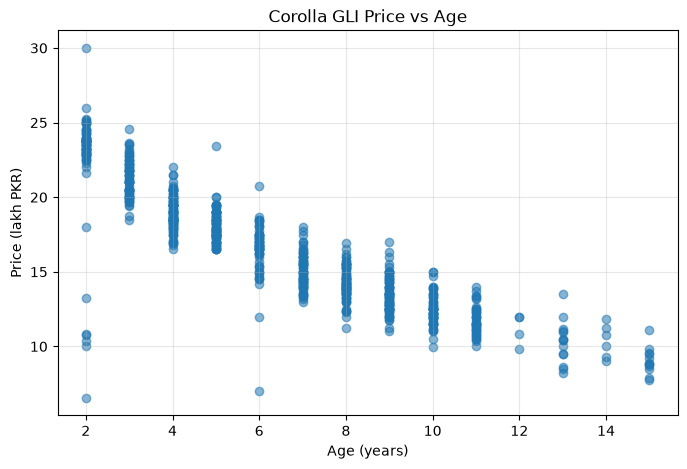

In [2]:
# T1: Load and explore the real data
df = pd.read_csv("pakistan_used_cars_clean.csv")
print("T1a - Original dataset shape:", df.shape)

# The supplied CSV does not contain Age, so calculate it using the lab's convention.
df["Age"] = 2020 - df["Year"]

gli = df[
    (df["Model"] == "Corolla GLI") &
    (df["Transaction Type"] == "Cash") &
    (df["Year"].between(2005, 2018)) &
    (df["Price_lakh"].between(5, 40))
].copy()

print("T1b - Filtered Corolla GLI shape:", gli.shape)
print("\\nT1c - Summary statistics:")
print(gli[["Age", "Price_lakh"]].describe())
print("\\nT1d - Correlation (Age vs Price_lakh):")
print(gli["Age"].corr(gli["Price_lakh"]))

plt.figure(figsize=(8, 5))
plt.scatter(gli["Age"], gli["Price_lakh"], alpha=0.55)
plt.title("Corolla GLI Price vs Age")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh PKR)")
plt.grid(True, alpha=0.3)
plt.show()

**T1 written answer:** A straight line is a sensible starting model because the correlation is strongly negative (about **−0.896**) and the scatter plot shows a clear downward trend: older Corolla GLI cars generally have lower prices. However, the points are spread around the trend, so age alone cannot explain every price difference.

## Task 2 · Features, target and the train/test split
- **(a)** `X` = the `Age` column as a **2-D** table, `y` = `Price_lakh`. Print both shapes.
- **(b)** Split 80 % train / 20 % test with `train_test_split(..., test_size=0.2, random_state=42)`. Print the four shapes.

In [3]:
# T2: Features, target and train/test split
X = gli[["Age"]]             # 2-D feature table
y = gli["Price_lakh"]        # 1-D target series

print("T2a - X shape:", X.shape)
print("T2a - y shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\\nT2b - X_train shape:", X_train.shape)
print("T2b - X_test shape:", X_test.shape)
print("T2b - y_train shape:", y_train.shape)
print("T2b - y_test shape:", y_test.shape)

T2a - X shape: (796, 1)
T2a - y shape: (796,)
\nT2b - X_train shape: (636, 1)
T2b - X_test shape: (160, 1)
T2b - y_train shape: (636,)
T2b - y_test shape: (160,)


## Task 3 · Least squares with NumPy (training data only)
Use only `X_train` and `y_train`, and NumPy (no scikit-learn):
- **(a)** The means x̄ and ȳ.
- **(b)** The slope b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² and the intercept b₀ = ȳ − b₁x̄.
- **(c)** **Write (Markdown):** what b₁ and b₀ mean for a Corolla GLI, with units.

In [4]:
# T3: Least squares with NumPy (training data only)
x = X_train["Age"].to_numpy()
target = y_train.to_numpy()

x_bar = np.mean(x)
y_bar = np.mean(target)

b1 = np.sum((x - x_bar) * (target - y_bar)) / np.sum((x - x_bar) ** 2)
b0 = y_bar - b1 * x_bar

print("T3a - Mean of Age (x_bar):", x_bar)
print("T3a - Mean of Price (y_bar):", y_bar)
print("T3b - Slope (b1):", b1)
print("T3b - Intercept (b0):", b0)

T3a - Mean of Age (x_bar): 6.382075471698113
T3a - Mean of Price (y_bar): 16.653325314465405
T3b - Slope (b1): -1.1459556866983842
T3b - Intercept (b0): 23.96690099419613


**T3c written answer:** The slope is about **−1.146 lakh per year**. This means that, according to the fitted line, each additional year of age is associated with an average decrease of about **1.146 lakh PKR** in the predicted Corolla GLI price. The intercept is about **23.967 lakh PKR**; it is the model's predicted price when Age = 0 (a year-2020 car under this age convention).

## Task 4 · Train the model with scikit-learn
- **(a)** Create a `LinearRegression()` model, fit it on the **training** data and print the slope (`coef_`) and intercept (`intercept_`).
- **(b)** Show with `np.isclose` that they equal your Task 3 values.

In [5]:
# T4: Train the model with scikit-learn
model = LinearRegression()
model.fit(X_train, y_train)

sk_slope = model.coef_[0]
sk_intercept = model.intercept_

print("T4a - Scikit-learn slope:", sk_slope)
print("T4a - Scikit-learn intercept:", sk_intercept)
print("T4b - Slopes are equal:", np.isclose(sk_slope, b1))
print("T4b - Intercepts are equal:", np.isclose(sk_intercept, b0))

T4a - Scikit-learn slope: -1.1459556866983838
T4a - Scikit-learn intercept: 23.966900994196127
T4b - Slopes are equal: True
T4b - Intercepts are equal: True


## Task 5 · Evaluate on the test set
- **(a)** Predict the test prices. Compute MAE, MSE, RMSE and R² **with the formulas** in NumPy.
- **(b)** Check MAE, MSE and R² with `sklearn.metrics`.
- **(c)** Train R² and test R². Is the model overfitting?
- **(d)** Baseline: predict the **training mean** for every test ad. Its MAE and R².

**Write (Markdown):** explain MAE and R² of your model in plain words, and how much better it is than the baseline.

In [6]:
# T5: Evaluate on the test set
y_pred = model.predict(X_test)

# Metrics calculated directly with NumPy formulas
errors = y_test.to_numpy() - y_pred
mae = np.mean(np.abs(errors))
mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)
r2 = 1 - (np.sum(errors ** 2) / np.sum((y_test.to_numpy() - np.mean(y_test)) ** 2))

print("T5a - MAE:", mae)
print("T5a - MSE:", mse)
print("T5a - RMSE:", rmse)
print("T5a - R2:", r2)

# Verify using scikit-learn metrics
print("\\nT5b - sklearn MAE:", mean_absolute_error(y_test, y_pred))
print("T5b - sklearn MSE:", mean_squared_error(y_test, y_pred))
print("T5b - sklearn R2:", r2_score(y_test, y_pred))

train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)
print("\\nT5c - Training R2:", train_r2)
print("T5c - Testing R2:", test_r2)

# Baseline: always predict the training mean
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)
print("\\nT5d - Baseline MAE:", baseline_mae)
print("T5d - Baseline R2:", baseline_r2)
print("MAE improvement over baseline (lakh):", baseline_mae - mae)

T5a - MAE: 1.1848658196422566
T5a - MSE: 2.704315367423671
T5a - RMSE: 1.644480272737764
T5a - R2: 0.8451747677868002
\nT5b - sklearn MAE: 1.1848658196422566


T5b - sklearn MSE: 2.704315367423671
T5b - sklearn R2: 0.8451747677868002
\nT5c - Training R2: 0.7896560758820064
T5c - Testing R2: 0.8451747677868002
\nT5d - Baseline MAE: 3.5043950314465406
T5d - Baseline R2: -0.006377644420647366
MAE improvement over baseline (lakh): 2.319529211804284


**T5 written answer:** The test MAE is about **1.185 lakh PKR**, so predictions are off by about Rs. 118,487 on average. The test R² is about **0.845**, meaning Age explains about 84.5% of the variation in test prices compared with guessing the test mean. The baseline MAE is about **3.504 lakh**, while our model's MAE is about **1.185 lakh**; therefore, the model reduces the average absolute error by about **2.320 lakh PKR**. Training R² is about 0.790 and test R² is about 0.845. Since the test score is not lower than the training score, these results do not show evidence of overfitting.

## Task 6 · Visualise the line and the errors
- **(a)** One plot: training ads (grey), test ads, and the fitted line. Title, labels, legend.
- **(b)** A residual plot for the test set: residual (y − ŷ) against predicted price, with a line at 0.
- **(c)** The five test ads with the largest absolute error: `Year`, `KMs Driven`, `Registered City`, actual and predicted price.

**Write (Markdown):** does the residual plot show a curve or a funnel? Are the largest errors mistakes of the model or of the data?

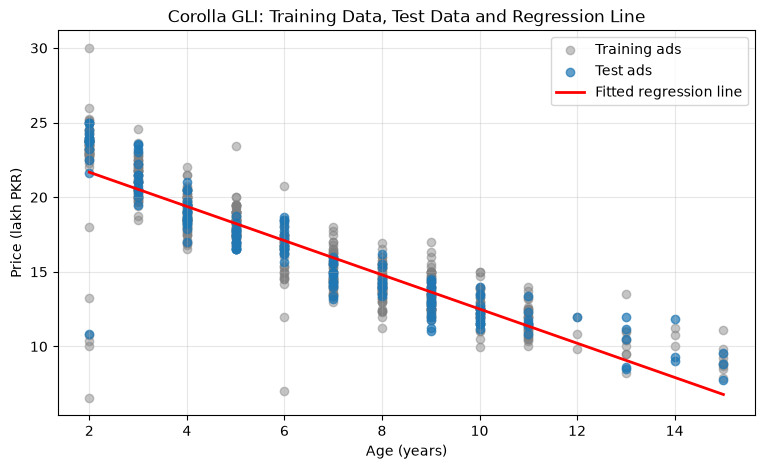

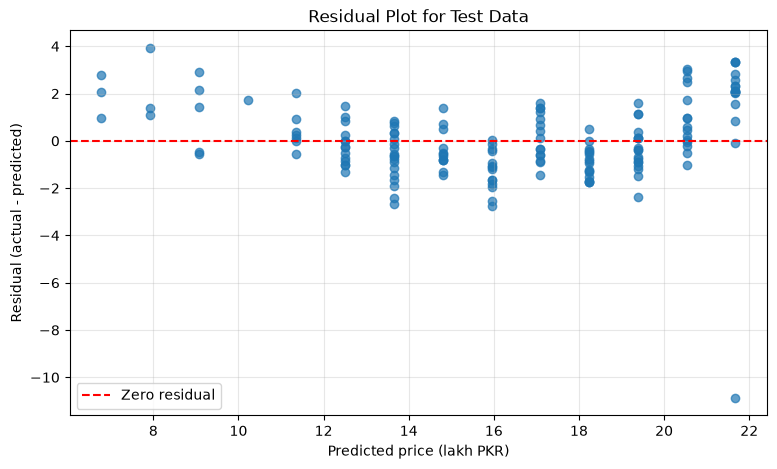

T6c - Five test ads with largest absolute errors:


,Year,KMs Driven,Registered City,Actual Price_lakh,Predicted Price_lakh,Absolute Error
18857,2018,NaN,Unknown,10.80,21.675,10.875
20280,2006,220000.0,Islamabad,11.85,7.924,3.926
17363,2018,NaN,Unknown,25.00,21.675,3.325
18980,2018,NaN,Unknown,25.00,21.675,3.325
16557,2018,300.0,Unknown,25.00,21.675,3.325


In [7]:
# T6: Visualise the line and the errors
plt.figure(figsize=(9, 5))
plt.scatter(X_train["Age"], y_train, color="grey", alpha=0.45, label="Training ads")
plt.scatter(X_test["Age"], y_test, alpha=0.7, label="Test ads")
age_line = np.linspace(X["Age"].min(), X["Age"].max(), 100)
price_line = model.predict(pd.DataFrame({"Age": age_line}))
plt.plot(age_line, price_line, color="red", linewidth=2, label="Fitted regression line")
plt.title("Corolla GLI: Training Data, Test Data and Regression Line")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh PKR)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Residual plot for test records
residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(9, 5))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--", label="Zero residual")
plt.title("Residual Plot for Test Data")
plt.xlabel("Predicted price (lakh PKR)")
plt.ylabel("Residual (actual - predicted)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Five test ads with the largest absolute errors
largest_errors = gli.loc[X_test.index, ["Year", "KMs Driven", "Registered City"]].copy()
largest_errors["Actual Price_lakh"] = y_test
largest_errors["Predicted Price_lakh"] = y_pred
largest_errors["Absolute Error"] = np.abs(residuals)
print("T6c - Five test ads with largest absolute errors:")
display(largest_errors.nlargest(5, "Absolute Error").round(3))

**T6 written answer:** The residual plot does not show a clear curve or funnel; most points are scattered around the zero line. However, there is one very large negative residual (about −10.88 lakh), which is an outlier. The largest errors are not automatically coding mistakes: price also depends on mileage, condition, registration city and other factors. For example, the largest-error record is a 2018 car listed at 10.8 lakh, while the age-only model predicts about 21.67 lakh. This may reflect missing information or an unusual advertisement.

## Task 7 · Use the model
- **(a)** Predict the price of a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 − year), using a DataFrame with an `Age` column.
- **(b)** Predict the price of a 1995 Corolla GLI (age 25).

**Write (Markdown):** is the answer in (b) believable? Why not?

In [8]:
# T7: Use the model
prediction_years = [2018, 2015, 2010]
prediction_ages = [2020 - year for year in prediction_years]
prediction_input = pd.DataFrame({"Age": prediction_ages})
predicted_prices = model.predict(prediction_input)

print("T7a - Predicted prices:")
for year, age, price in zip(prediction_years, prediction_ages, predicted_prices):
    print(f"Year {year}, Age {age}: {price:.2f} lakh PKR")

# A 1995 car has age 25 using the same convention
old_car_input = pd.DataFrame({"Age": [2020 - 1995]})
old_car_prediction = model.predict(old_car_input)[0]
print(f"\\nT7b - Year 1995, Age 25: {old_car_prediction:.2f} lakh PKR")

T7a - Predicted prices:
Year 2018, Age 2: 21.67 lakh PKR
Year 2015, Age 5: 18.24 lakh PKR
Year 2010, Age 10: 12.51 lakh PKR
\nT7b - Year 1995, Age 25: -4.68 lakh PKR


**T7 written answer:** The prediction for a 1995 Corolla GLI is not believable as a real market price because the model predicts a negative value (about **−4.68 lakh PKR**). The model was trained on cars aged 2–15 years, while this car has age 25. This is extrapolation far outside the training range. A straight line continues decreasing even where real used-car prices cannot become negative.

## Task 8 · Reflection
Write 3–5 sentences: the steps you followed to build the model, why the model is judged on the test set and not the training set, which number you would tell a car buyer and why, and one limitation of using age alone.

**T8 reflection:** I loaded the cleaned Pakistan used-cars dataset, filtered Corolla GLI cash advertisements, calculated car age, explored the relationship, and split the data into training and testing sets. I trained a simple linear regression model using both NumPy's least-squares formula and scikit-learn, then evaluated it on unseen test data. The test set is important because it shows how the model performs on data it did not learn from. I would tell a buyer the MAE (about Rs. 118,487) because it describes the average prediction error in understandable money units. A limitation is that age alone ignores mileage, condition, city and other factors that affect a car's price.